# Sensores activos: radar, InSAR y LiDAR

Los sensores activos emiten su propia energía y registran el eco que regresa de la superficie. No dependen del Sol, de modo que funcionan de día y de noche, y los radares, que trabajan con microondas, atraviesan las nubes, una ventaja decisiva en los Andes tropicales, donde una imagen óptica sin nubes puede tardar meses. Este capítulo trata el radar de apertura sintética (SAR), su uso interferométrico para medir deformaciones del terreno (InSAR) y el LiDAR {cite}`moreira2013,lillesand2015`.

## Principio del radar

Un radar de imágenes emite pulsos de microondas hacia un lado de la trayectoria de la plataforma (visión lateral) y mide el tiempo de retorno y la intensidad del eco. El tiempo de retorno da la distancia oblicua al objeto, $R = c\,t/2$, y la intensidad, la retrodispersión, depende de las propiedades del terreno. La visión lateral es necesaria porque con visión vertical dos puntos a la misma distancia a ambos lados del nadir devolverían el eco al mismo tiempo y no se podrían separar.

Las bandas de radar se designan con letras heredadas del uso militar. La banda X (unos 3 cm, TerraSAR-X, COSMO-SkyMed) da la mayor resolución pero penetra poco en la vegetación; la banda C (5.6 cm, Sentinel-1, RADARSAT) es el compromiso más usado; la banda L (24 cm, ALOS-2, NISAR) penetra el dosel de la vegetación y mantiene mejor la coherencia en zonas boscosas; la banda P (unos 70 cm, BIOMASS) penetra todavía más y se usa para estimar la biomasa forestal. En general, cuanto mayor es la longitud de onda, mayor es la penetración en la vegetación y en suelos secos.

## Resolución del radar

La resolución en la dirección de la distancia (range) depende de la duración del pulso $\tau$: dos objetos se separan si sus ecos no se superponen, es decir, si están a más de $c\,\tau/2$ en distancia oblicua. En el terreno, esa distancia se proyecta como $c\,\tau / (2 \cos\theta)$, donde $\theta$ es el ángulo de depresión; por eso la resolución en distancia mejora lejos del nadir. En la práctica se usan pulsos modulados en frecuencia (chirps) que, procesados, equivalen a pulsos muy cortos. La resolución en la dirección de vuelo (azimut) de un radar de apertura real es el ancho del haz, proporcional a $\lambda R / L$, con $L$ la longitud de la antena; para un satélite a 800 km con una antena de 10 m en banda C sería de varios kilómetros. El radar de apertura sintética resuelve el problema: mientras el satélite avanza, un mismo punto queda dentro del haz durante cientos de pulsos, y el procesamiento combina todos esos ecos como si vinieran de una antena virtual de kilómetros de largo, con lo que la resolución en azimut llega a ser del orden de la mitad de la longitud de la antena real, independiente de la distancia.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage
plt.rcParams['figure.dpi'] = 80
c = 3e8

for tau_us in [0.1, 0.05]:
    for theta in [20, 40]:
        print(f'pulso {tau_us} µs, ángulo de depresión {theta}° -> resolución en distancia sobre el terreno '
              f'{c*tau_us*1e-6/(2*np.cos(np.radians(theta))):.1f} m')
lam, R, L = 0.056, 850e3, 12.0
print(f'Apertura real (banda C, R = 850 km, antena 12 m): resolución en azimut {lam*R/L/1e3:.1f} km')
print(f'Apertura sintética: resolución en azimut del orden de L/2 = {L/2:.0f} m, longitud de la antena sintética {lam*R/L/1e3:.1f} km')

pulso 0.1 µs, ángulo de depresión 20° -> resolución en distancia sobre el terreno 16.0 m
pulso 0.1 µs, ángulo de depresión 40° -> resolución en distancia sobre el terreno 19.6 m
pulso 0.05 µs, ángulo de depresión 20° -> resolución en distancia sobre el terreno 8.0 m
pulso 0.05 µs, ángulo de depresión 40° -> resolución en distancia sobre el terreno 9.8 m
Apertura real (banda C, R = 850 km, antena 12 m): resolución en azimut 4.0 km
Apertura sintética: resolución en azimut del orden de L/2 = 6 m, longitud de la antena sintética 4.0 km


## Retrodispersión

La intensidad del eco depende de la rugosidad de la superficie comparada con la longitud de onda, de la geometría local y de la constante dieléctrica, que crece con la humedad. Una superficie lisa a la escala de la longitud de onda, como el agua en calma, una pista o una playa, produce reflexión especular lejos del sensor y se ve oscura. Una superficie rugosa dispersa en todas las direcciones y devuelve parte de la energía: se ve en tonos medios. La vegetación produce dispersión de volumen, múltiples rebotes dentro del dosel. Los ángulos rectos formados por edificios y el suelo, o por troncos y el suelo inundado, producen doble rebote y aparecen muy brillantes. La humedad del suelo aumenta la retrodispersión, lo que permite estimarla, y las zonas inundadas se reconocen por su respuesta oscura. La polarización de la señal emitida y recibida (VV, VH, HH, HV) aporta información adicional: la polarización cruzada (VH, HV) es sensible sobre todo a la dispersión de volumen de la vegetación.

## Distorsiones del relieve

La geometría lateral produce distorsiones características en terreno montañoso. Las laderas que miran hacia el radar se ven acortadas (escorzo, foreshortening) y brillantes; si son más empinadas que el ángulo de incidencia, su cima devuelve el eco antes que su base y la ladera aparece invertida (inversión por relieve, layover). Las laderas opuestas, si son más empinadas que el ángulo de depresión, no reciben señal y quedan en sombra de radar. Estas zonas no tienen información útil, y en los Andes pueden cubrir una parte importante de la escena; combinar órbitas ascendentes y descendentes reduce el problema. La celda siguiente calcula las tres zonas para un perfil topográfico.

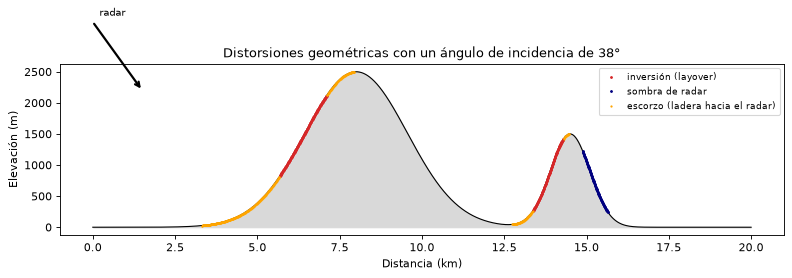

Fracción del perfil en inversión: 11.8%, en sombra: 3.9%


In [2]:
x = np.linspace(0, 20000, 2000)
z = 2500 * np.exp(-((x - 8000) / 2200)**2) + 1500 * np.exp(-((x - 14500) / 850)**2)
inc = np.radians(38)                                       # ángulo de incidencia; el radar está a la izquierda
pend = np.degrees(np.arctan(np.gradient(z, x)))
layover = pend > np.degrees(inc)                           # ladera hacia el radar más empinada que el ángulo de incidencia
sombra = np.zeros_like(x, bool)
for k in range(len(x)):
    linea = z[:k] - (x[k] - x[:k]) / np.tan(inc)          # rayo que pasa rozando los puntos anteriores
    sombra[k] = k > 0 and z[k] < linea.max()
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.fill_between(x / 1e3, 0, z, color='0.85')
ax.plot(x / 1e3, z, 'k', lw=1)
ax.plot(x[layover] / 1e3, z[layover], '.', color='tab:red', ms=3, label='inversión (layover)')
ax.plot(x[sombra] / 1e3, z[sombra], '.', color='navy', ms=3, label='sombra de radar')
esc = (pend > 3) & ~layover
ax.plot(x[esc] / 1e3, z[esc], '.', color='orange', ms=2, label='escorzo (ladera hacia el radar)')
ax.annotate('', xy=(1.5, 2200), xytext=(0, 3300), arrowprops=dict(arrowstyle='->', lw=2))
ax.text(0.2, 3400, 'radar', fontsize=9)
ax.set_xlabel('Distancia (km)'); ax.set_ylabel('Elevación (m)'); ax.legend(fontsize=8, loc='upper right')
ax.set_title(f'Distorsiones geométricas con un ángulo de incidencia de {np.degrees(inc):.0f}°')
plt.tight_layout(); plt.show()
print(f'Fracción del perfil en inversión: {layover.mean():.1%}, en sombra: {sombra.mean():.1%}')

## Moteado (speckle)

Cada píxel de una imagen SAR contiene muchos dispersores elementales cuyos ecos se suman con fases aleatorias. La interferencia entre ellos produce el moteado, una variación granular de la intensidad entre píxeles vecinos aunque la superficie sea homogénea. Estadísticamente es un ruido multiplicativo: la intensidad de un píxel de una sola observación sigue una distribución exponencial alrededor del valor medio. Se reduce promediando varias observaciones independientes (procesamiento multilook), a costa de resolución, o con filtros adaptativos como el de Lee {cite}`lee1980`, que suavizan las zonas homogéneas y conservan los bordes. La celda siguiente simula una escena con moteado y la filtra.

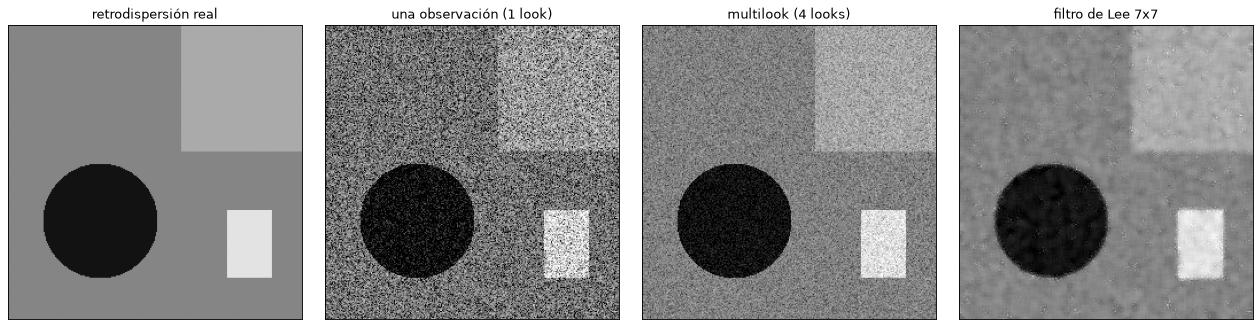

In [3]:
rng = np.random.default_rng(5)
n = 256
yy, xx = np.mgrid[0:n, 0:n]
sigma0 = np.full((n, n), 0.08)                                   # pasto
sigma0[(xx - 80)**2 + (yy - 170)**2 < 50**2] = 0.005             # lago (especular)
sigma0[(xx > 150) & (yy < 110)] = 0.2                            # bosque (volumen)
sigma0[(xx > 190) & (xx < 230) & (yy > 160) & (yy < 220)] = 0.8  # zona urbana (doble rebote)
def con_moteado(s, looks=1):
    return s * rng.gamma(looks, 1 / looks, s.shape)
def lee(img, tam=7, looks=1):
    media = ndimage.uniform_filter(img, tam)
    var = ndimage.uniform_filter(img**2, tam) - media**2
    cu2 = 1 / looks
    ci2 = var / np.maximum(media**2, 1e-12)
    w = np.clip(1 - cu2 / np.maximum(ci2, 1e-12), 0, 1)
    return media + w * (img - media)
un_look = con_moteado(sigma0)
cuatro = con_moteado(sigma0, 4)
fig, axs = plt.subplots(1, 4, figsize=(16, 4))
for a, im, t in zip(axs, [sigma0, un_look, cuatro, lee(un_look)],
                    ['retrodispersión real', 'una observación (1 look)', 'multilook (4 looks)', 'filtro de Lee 7x7']):
    a.imshow(10 * np.log10(np.clip(im, 1e-4, None)), cmap='gray', vmin=-25, vmax=2); a.set_title(t)
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

## Interferometría radar (InSAR)

El eco de radar tiene amplitud y fase. La fase registra la distancia entre la antena y el terreno en fracciones de la longitud de onda. Si se toman dos imágenes SAR del mismo lugar desde posiciones casi idénticas, la diferencia de fase entre ellas, el interferograma, depende de la topografía (porque las dos posiciones no son exactamente iguales), de la deformación del terreno entre las dos fechas, de la atmósfera y del ruido {cite}`hanssen2001`. Si la topografía se elimina con un modelo de elevación, lo que queda es la interferometría diferencial (DInSAR), que mide el desplazamiento del terreno en la dirección de visión del satélite (LOS) con precisión de centímetros o milímetros:

$$d_{LOS} = \frac{\lambda}{4\pi}\,\Delta\phi.$$

Cada ciclo completo de fase (una franja de colores) equivale a media longitud de onda de desplazamiento: 2.8 cm en banda C. La fase solo se conoce entre $-\pi$ y $\pi$ (está envuelta), y para obtener el desplazamiento total hay que desenvolverla, contando las franjas. La calidad del interferograma se mide con la coherencia, que baja cuando la superficie cambia entre las dos fechas, como ocurre con la vegetación densa, el agua o los movimientos rápidos.

Las aplicaciones geológicas son muchas: deformación cosísmica de los terremotos, inflación y deflación de volcanes, subsidencia por extracción de agua o por minería, y movimientos lentos de laderas. Con series de decenas de imágenes, las técnicas de dispersores persistentes (PS-InSAR) y de líneas base cortas (SBAS) obtienen series temporales de desplazamiento con precisión milimétrica. La celda siguiente simula el interferograma de una subsidencia y de un deslizamiento lento, con ruido atmosférico, y recupera el desplazamiento.

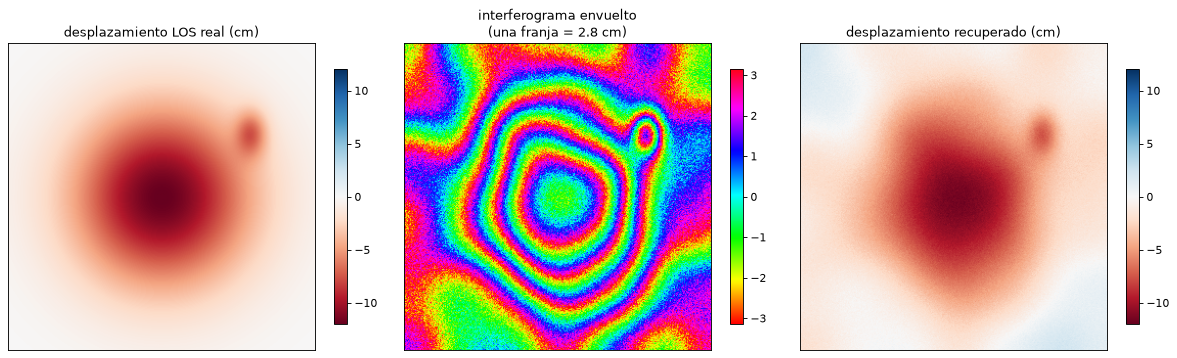

Franjas en la subsidencia: 4.3; error medio cuadrático 0.82 cm (incluye la atmósfera)


In [4]:
lam_c = 0.0555
n = 300
yy, xx = (np.mgrid[0:n, 0:n] - n / 2) * 40.0                     # píxeles de 40 m
subs = -0.12 * np.exp(-(xx**2 + yy**2) / (2 * 2500**2))         # subsidencia de 12 cm
desl = -0.05 * np.exp(-(((xx - 3500) / 600)**2 + ((yy + 2500) / 900)**2))   # deslizamiento lento, 5 cm
atm = ndimage.gaussian_filter(rng.normal(0, 1, (n, n)), 25); atm *= 0.008 / atm.std()
d_los = subs + desl
fase = 4 * np.pi / lam_c * (d_los + atm) + rng.normal(0, 0.4, (n, n))
envuelta = np.angle(np.exp(1j * fase))
# desenvolvimiento sencillo: integrar los gradientes de fase envuelta por filas y columnas (válido sin ruido fuerte)
def desenvolver(w):
    u = np.unwrap(w, axis=0)
    return np.unwrap(u, axis=1)
d_rec = desenvolver(envuelta) * lam_c / (4 * np.pi)
d_rec -= d_rec[5, 5] - (d_los + atm)[5, 5]
fig, axs = plt.subplots(1, 3, figsize=(15, 4.4))
h0 = axs[0].imshow(d_los * 100, cmap='RdBu', vmin=-12, vmax=12); axs[0].set_title('desplazamiento LOS real (cm)')
h1 = axs[1].imshow(envuelta, cmap='hsv'); axs[1].set_title(f'interferograma envuelto\n(una franja = {lam_c/2*100:.1f} cm)')
h2 = axs[2].imshow(d_rec * 100, cmap='RdBu', vmin=-12, vmax=12); axs[2].set_title('desplazamiento recuperado (cm)')
for a, h in zip(axs, [h0, h1, h2]):
    fig.colorbar(h, ax=a, shrink=0.8); a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()
print(f'Franjas en la subsidencia: {abs(subs.min())/(lam_c/2):.1f}; error medio cuadrático {100*np.sqrt(np.mean((d_rec-d_los)**2)):.2f} cm (incluye la atmósfera)')

## LiDAR

El LiDAR (Light Detection and Ranging) emite pulsos láser, usualmente en el infrarrojo cercano, y mide el tiempo de retorno de cada uno. Montado en un avión o un dron, con un GNSS y una unidad inercial que dan la posición y la actitud del sensor, produce una nube de millones de puntos con coordenadas tridimensionales y precisión de pocos centímetros. Un mismo pulso puede producir varios retornos: el primero en la copa de los árboles, otros en las ramas y el último, a menudo, en el suelo, porque una parte del haz encuentra un hueco en el dosel. Clasificando los puntos de suelo se obtiene un modelo digital del terreno (MDT) sin vegetación, y con los primeros retornos un modelo digital de superficie (MDS); su diferencia es la altura del dosel.

Para la geología, esta capacidad de ver el terreno bajo el bosque es la gran ventaja del LiDAR: revela escarpes de falla, cicatrices de deslizamientos antiguos, terrazas y abanicos que en las fotos quedan ocultos por la vegetación. La celda siguiente simula una nube de puntos sobre un terreno con un escarpe bajo un bosque y separa el terreno con un filtro sencillo de mínimos locales.

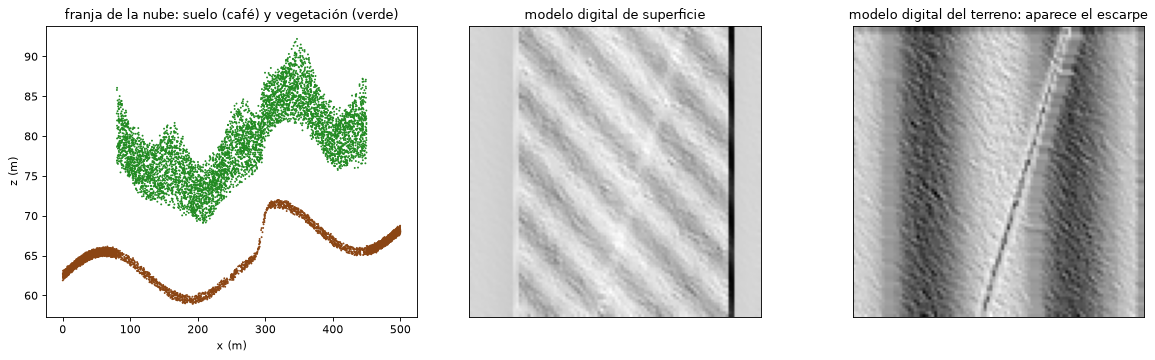

In [5]:
npts = 250000
px, py = rng.uniform(0, 500, npts), rng.uniform(0, 500, npts)
terreno = lambda x, y: 50 + 0.05 * y + 6 / (1 + np.exp(-(x - 0.3 * y - 220) / 3)) + 3 * np.sin(x / 40)
zs = terreno(px, py)
bosque = (px > 80) & (px < 450)
altura_copa = np.where(bosque, 18 + 4 * np.sin(px / 15) * np.cos(py / 17), 0)
llega_suelo = rng.random(npts) < np.where(bosque, 0.2, 1.0)               # solo el 20 % de los pulsos llega al suelo en el bosque
pz = np.where(llega_suelo, zs, zs + altura_copa * rng.uniform(0.6, 1.0, npts)) + rng.normal(0, 0.08, npts)
celda = 5.0
ix, iy = (px // celda).astype(int), (py // celda).astype(int)
nc = int(500 / celda)
mds = np.full((nc, nc), -np.inf); mdt = np.full((nc, nc), np.inf)
np.maximum.at(mds, (iy, ix), pz); np.minimum.at(mdt, (iy, ix), pz)
def rellenar(a):
    vacias = ~np.isfinite(a)
    idx = ndimage.distance_transform_edt(vacias, return_distances=False, return_indices=True)
    return a[tuple(idx)]
mds, mdt = rellenar(mds), rellenar(mdt)
mdt = ndimage.grey_opening(mdt, size=5)                                   # elimina mínimos que no son suelo
from matplotlib.colors import LightSource
ls = LightSource(315, 45)
fig, axs = plt.subplots(1, 3, figsize=(15, 4.6))
sel = (py > 240) & (py < 260)
axs[0].scatter(px[sel], pz[sel], s=0.5, c=np.where(llega_suelo[sel], 'saddlebrown', 'forestgreen')); axs[0].set_title('franja de la nube: suelo (café) y vegetación (verde)')
axs[0].set_xlabel('x (m)'); axs[0].set_ylabel('z (m)')
axs[1].imshow(ls.hillshade(mds, dx=celda, dy=celda), cmap='gray', origin='lower'); axs[1].set_title('modelo digital de superficie')
axs[2].imshow(ls.hillshade(mdt, dx=celda, dy=celda, vert_exag=3), cmap='gray', origin='lower'); axs[2].set_title('modelo digital del terreno: aparece el escarpe')
for a in axs[1:]: a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

## Para profundizar

El tutorial de {cite:t}`moreira2013` es la mejor introducción al SAR y está enlazado en la página del curso, igual que el curso ARSET de la NASA sobre radar. {cite:t}`hanssen2001` es la referencia de la interferometría. El capítulo 6 de {cite}`lillesand2015` trata el radar y el LiDAR con ejemplos de aplicaciones. El taller de radar del curso procesa un par de imágenes Sentinel-1.